<a href="https://colab.research.google.com/github/vlad-budeanu/calcium-image-denoising/blob/main/Calcium_denoising.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!pip install -q gdown
import gdown
#Descarcam fisierele F0.tif, F1.tif pe discul local temporar din Colab
#F0.tif: Ground Truth
#F1.tif: Imagine cu zgomot
id_F0='1B5x5vXUI6ZmJH1vHvY-Z9MDjPxjcMhMi'
id_F1='1Va_HeD5tRSdASZIOOnvEqzt803x9Y-Fb'

gdown.download(id=id_F0, output='/content/F0.tif', quiet=False)
gdown.download(id=id_F1, output='/content/F1.tif', quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=1B5x5vXUI6ZmJH1vHvY-Z9MDjPxjcMhMi
From (redirected): https://drive.google.com/uc?id=1B5x5vXUI6ZmJH1vHvY-Z9MDjPxjcMhMi&confirm=t&uuid=3762cef7-8d72-41fa-b491-467898a2567d
To: /content/F0.tif
100%|██████████| 721M/721M [00:10<00:00, 71.9MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1Va_HeD5tRSdASZIOOnvEqzt803x9Y-Fb
From (redirected): https://drive.google.com/uc?id=1Va_HeD5tRSdASZIOOnvEqzt803x9Y-Fb&confirm=t&uuid=f3a46cea-6e29-4d68-a02d-221f1ab9698c
To: /content/F1.tif
100%|██████████| 721M/721M [00:07<00:00, 100MB/s]


'/content/F1.tif'

In [6]:
# Instalarea pachetelor necesare
!pip install -q tifffile scikit-image opencv-python

# Importarea bibliotecilor
import os
import numpy as np
import tifffile
import matplotlib.pyplot as plt
from keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, concatenate, Add
from keras.models import Model
from keras.callbacks import EarlyStopping, ModelCheckpoint
from keras.optimizers import Adam
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

print("Bibliotecile au fost importate cu succes")

Bibliotecile au fost importate cu succes


In [7]:
#Incarcarea datelor
cale_zgomot = '/content/F1.tif'
cale_ground_truth = '/content/F0.tif'

if not os.path.exists(cale_zgomot):
    print(f"Nu se gaseste calea catre {cale_zgomot}")
elif not os.path.exists(cale_ground_truth):
    print(f"Nu se gaseste calea catre {cale_ground_truth}")
else:
    # crearea legaturii virtuale (memory mapping)
    #datele sunt incarcate atunci cand este necesar
    memmap_zgomot = tifffile.memmap(cale_zgomot)
    memmap_gt = tifffile.memmap(cale_ground_truth)

    print(f"Total cadre F1 (Zgomot): {memmap_zgomot.shape}")
    print(f"Total cadre F0 (GT): {memmap_gt.shape}")

    # Verificăm dacă fișierele se potrivesc ca dimensiune
    if memmap_zgomot.shape != memmap_gt.shape:
      print("Fisierele nu au același numar de cadre/aceeasi rezolutie")

Total cadre F1 (Zgomot): (1500, 490, 490)
Total cadre F0 (GT): (1500, 490, 490)


In [8]:
#Preprocesarea datelor
# Alegem primele 600 de cadre și le încărcăm în RAM
# Nu se pot prelucra toate datele in acelasi timp pentru ca ar umple RAM-ul
max_cadre = 600
subset_zgomot = memmap_zgomot[:max_cadre]
subset_gt = memmap_gt[:max_cadre]

#incarcarea efectiva in RAM
array_zgomot_ram = np.array(subset_zgomot)
array_gt_ram = np.array(subset_gt)

#transformarea la float32 pentru a avea o mai buna precizie
video_data_zgomot = array_zgomot_ram.astype(np.float32)
video_data_gt = array_gt_ram.astype(np.float32)

print(f"Date incarcate în RAM: Zgomot {video_data_zgomot.shape}")
print(f"Date incarcate în RAM: GT {video_data_gt.shape}")

# Normalizarea datelor
# Se foloseste acelasi maxim global
# Se doreste ca toate datele sa fie intre [0,1]
# Se imparte la acelasi maxim pentru a avea aceeasi scara de comparatie
train_idx=int(len(video_data_gt)*0.7)
max_global = max(np.max(video_data_zgomot[:train_idx]), np.max(video_data_gt[:train_idx]))
zgomot_norm = video_data_zgomot / max_global
gt_norm = video_data_gt / max_global
print(f"Maximul global este {max_global}")
print(f"Datele au fost normalizate")

# taierea marginilor pentru a fi multimplu de 4
# necesar pentru U-Net
h, w = zgomot_norm.shape[1:3]
new_h= h - (h % 4)
new_w = w - (w % 4)
zgomot_norm = zgomot_norm[:, :new_h, :new_w]
gt_norm = gt_norm[:, :new_h, :new_w]

# Adaugare canal de culoare
# Se adauga la final, exista un singur canal de culoare
# Necesar pentru TensorFlow
zgomot_norm = np.expand_dims(zgomot_norm, axis=-1)
gt_norm = np.expand_dims(gt_norm, axis=-1)

# Impartirea cadrelor: 70% antrenament, 15% test, 15% verificare finala
split_1 = int(max_cadre * 0.70)
split_2 = int(max_cadre * 0.85)

# Setul de antrenament (primele 70%)
gt_train = gt_norm[:split_1]
zgomot_train = zgomot_norm[:split_1]

# Setul de validare (următoarele 15%)
gt_val = gt_norm[split_1:split_2]
zgomot_val = zgomot_norm[split_1:split_2]

# Setul de test final (ultimele 15%)
gt_test = gt_norm[split_2:]
zgomot_test = zgomot_norm[split_2:]

print(f"Cadre antrenament (70%): {len(gt_train)}")
print(f"Cadre validare (15%): {len(gt_val)}")
print(f"Cadre test final (15%): {len(gt_test)}")

Date incarcate în RAM: Zgomot (600, 490, 490)
Date incarcate în RAM: GT (600, 490, 490)
Maximul global este 9357.0
Datele au fost normalizate
Cadre antrenament (70%): 420
Cadre validare (15%): 90
Cadre test final (15%): 90


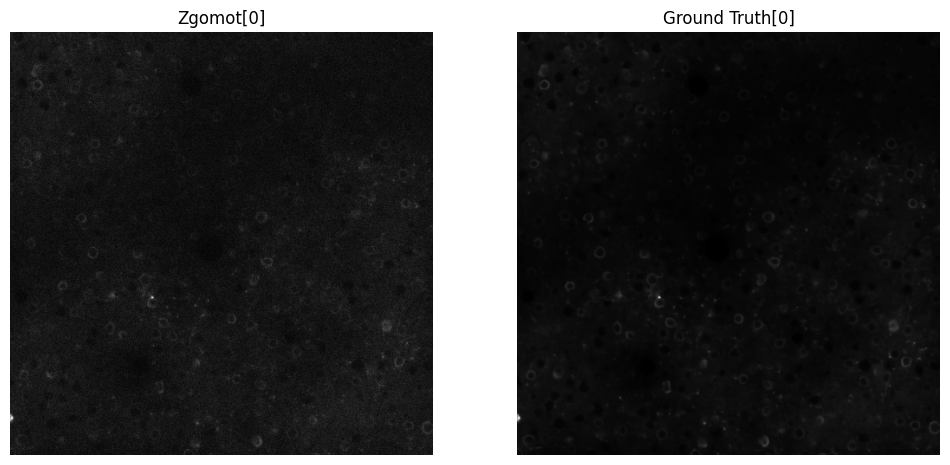

In [9]:
# Vizualizarea datelor inainte de antrenament
plt.figure(figsize=(12, 6))

# Afisare zgomot
# .squeeze() elimina canalul de culoare
plt.subplot(1, 2, 1)
plt.imshow(zgomot_train[0].squeeze(), cmap='gray')
plt.title("Zgomot[0]")
plt.axis('off')

# Afisare Ground Truth
plt.subplot(1, 2, 2)
plt.imshow(gt_train[0].squeeze(), cmap='gray')
plt.title("Ground Truth[0]")
plt.axis('off')

plt.show()

In [10]:
# Construire retea U-Net
# Facem un Residual U-Net
# Reteaua se focuseaza pe descoperirea zgomotului pentru a sti ce trebuie eliminat

def residual_unet(input_shape):
  # Introducerea datelor
    inputs = Input(input_shape)

    # Encoder (extragerea trasaturilor)
    # se parcurg patrate de 3*3 pixeli folosind 32 de filtre si se cauta pixelii de zgomot
    # relu transforma numerele negative in 0
    c1 = Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
    c1 = Conv2D(32, (3, 3), activation='relu', padding='same')(c1)
    # Impartirea imaginii in jumatate pentru a ramane doar pixelii esentiali
    p1 = MaxPooling2D((2, 2))(c1)

    # Se face de 2 ori convolutia pentru a mari perimetrul unde se uita, dar fara a consuma multe date
    c2 = Conv2D(64, (3, 3), activation='relu', padding='same')(p1)
    c2 = Conv2D(64, (3, 3), activation='relu', padding='same')(c2)
    p2 = MaxPooling2D((2, 2))(c2)

    # Bottleneck (Punctul cel mai adanc al retelei)
    c3 = Conv2D(128, (3, 3), activation='relu', padding='same')(p2)
    c3 = Conv2D(128, (3, 3), activation='relu', padding='same')(c3)

    # Decoder (Reconstrucția imaginii)
    # dublarea imaginii(deoarece a fost facut MaxPooling2D)
    u4 = UpSampling2D((2, 2))(c3)
    #deoarece imaginea a fost marita are nevoie de pattern-ul initial pentru a sti unde sa puna pixelii
    u4 = concatenate([u4, c2])
    # Se uita la datele primite si contureaza ce a descoperit cu un nivel mai jos
    # Accentueaza zgomotul si ignora neuronii
    c4 = Conv2D(64, (3, 3), activation='relu', padding='same')(u4)
    c4 = Conv2D(64, (3, 3), activation='relu', padding='same')(c4)

    u5 = UpSampling2D((2, 2))(c4)
    u5 = concatenate([u5, c1])
    c5 = Conv2D(32, (3, 3), activation='relu', padding='same')(u5)
    c5 = Conv2D(32, (3, 3), activation='relu', padding='same')(c5)

    # Invata sa extraga doar harta zgomotului
    # 'linear' inseamna ca pot exista si numere negative
    # Se ia pixel cu pixel si se construieste harta zgomotului
    # Zgomotul a facut pixelul prea luminos, iar in harta va fi cu - pentru a putea fi apoi adunat
    harta_zgomot = Conv2D(1, (1, 1), activation='linear')(c5)

    # Conexiunea reziduală: Scădem/Adunăm harta zgomotului din imaginea originală
    outputs = Add()([inputs, harta_zgomot])

    model = Model(inputs=[inputs], outputs=[outputs])
    # modelul Adam se uita cat de eronata este reteaua si in ce directie trebuie sa o ia
    # learning_reate-ul este mic pentru a nu sari peste detalii
    # mse - mean square error - dorinta de a ajunge la 0(match perfect cu gt)
    model.compile(optimizer=Adam(learning_rate=0.0005), loss='mse')
    return model

# Apelarea functiei
# Nu i se da si primul parametru(nr de cadre) pentru ca el are nevoie doar de dimensiunile efective
model = residual_unet(zgomot_train.shape[1:])
# Afisarea structurii
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 488, 488,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 488, 488,  │        320 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 488, 488,  │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 244, 244,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 244, 244,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 244, 244,  │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 122, 122,  │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 122, 122,  │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 122, 122,  │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 244, 244,  │          0 │ conv2d_5[0][0]    │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 244, 244,  │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 192)              │            │ conv2d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 244, 244,  │    110,656 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 244, 244,  │     36,928 │ conv2d_6[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 488, 488,  │          0 │ conv2d_7[0][0]    │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 488, 488,  │          0 │ up_sampling2d_1[… │
│ (Concatenate)       │ 96)               │            │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 488, 488,  │     27,680 │ concatenate_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 488, 488,  │      9,248 │ conv2d_8[0][0]  

 Total params: 470,977 (1.80 MB)

 Trainable params: 470,977 (1.80 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Antrenarea modelului
# Salveaza cel mai bun rezultat optinut
# Daca eroarea este mai mica -> rezultatul este mai bun
checkpoint = ModelCheckpoint('model_rezidual_calciu.keras', monitor='val_loss', save_best_only=True)
# Daca dupa 5 epoci reteaua nu se imbunatateste -> se opreste
early_stopper = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Prelucreaza cate 4 imagini in acelasi timp pentru a nu incarca RAM-ul
istoric = model.fit(
    zgomot_train, gt_train,
    validation_data=(zgomot_val, gt_val),
    batch_size=4,
    epochs=25,
    callbacks=[checkpoint, early_stopper]
)
print("Antrenamentul s-a terminat cu succes")

Epoch 1/25
105/105 ━━━━━━━━━━━━━━━━━━━━ 80s 371ms/step - loss: 2.5440e-05 - val_loss: 1.1015e-05
Epoch 2/25
105/105 ━━━━━━━━━━━━━━━━━━━━ 24s 225ms/step - loss: 8.9855e-06 - val_loss: 1.0272e-05
Epoch 3/25
105/105 ━━━━━━━━━━━━━━━━━━━━ 24s 228ms/step - loss: 8.5403e-06 - val_loss: 9.4992e-06
Epoch 4/25
105/105 ━━━━━━━━━━━━━━━━━━━━ 24s 231ms/step - loss: 8.3125e-06 - val_loss: 9.2155e-06
Epoch 5/25
105/105 ━━━━━━━━━━━━━━━━━━━━ 25s 237ms/step - loss: 8.1433e-06 - val_loss: 9.1231e-06
Epoch 6/25
105/105 ━━━━━━━━━━━━━━━━━━━━ 26s 246ms/step - loss: 8.0602e-06 - val_loss: 8.9773e-06
Epoch 7/25
105/105 ━━━━━━━━━━━━━━━━━━━━ 25s 239ms/step - loss: 7.9816e-06 - val_loss: 8.8883e-06
Epoch 8/25
105/105 ━━━━━━━━━━━━━━━━━━━━ 25s 238ms/step - loss: 7.9310e-06 - val_loss: 8.8215e-06
Epoch 9/25
105/105 ━━━━━━━━━━━━━━━━━━━━ 25s 239ms/step - loss: 7.8565e-06 - val_loss: 8.7595e-06
Epoch 10/25
105/105 ━━━━━━━━━━━━━━━━━━━━ 25s 240ms/step - loss: 7.7753e-06 - val_loss: 8.6953e-06
Epoch 11/25
105/105 ━━━━━━━━━

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step
Rezultate medii pe tot setul de date: 90 cadre
Medie PSNR zgomot: 40.24
Medie PSNR pred: 51.07
Medie SSIM zgomot: 0.909
Medie SSIM pred: 0.992
Cadrul ales pentru testare este 38


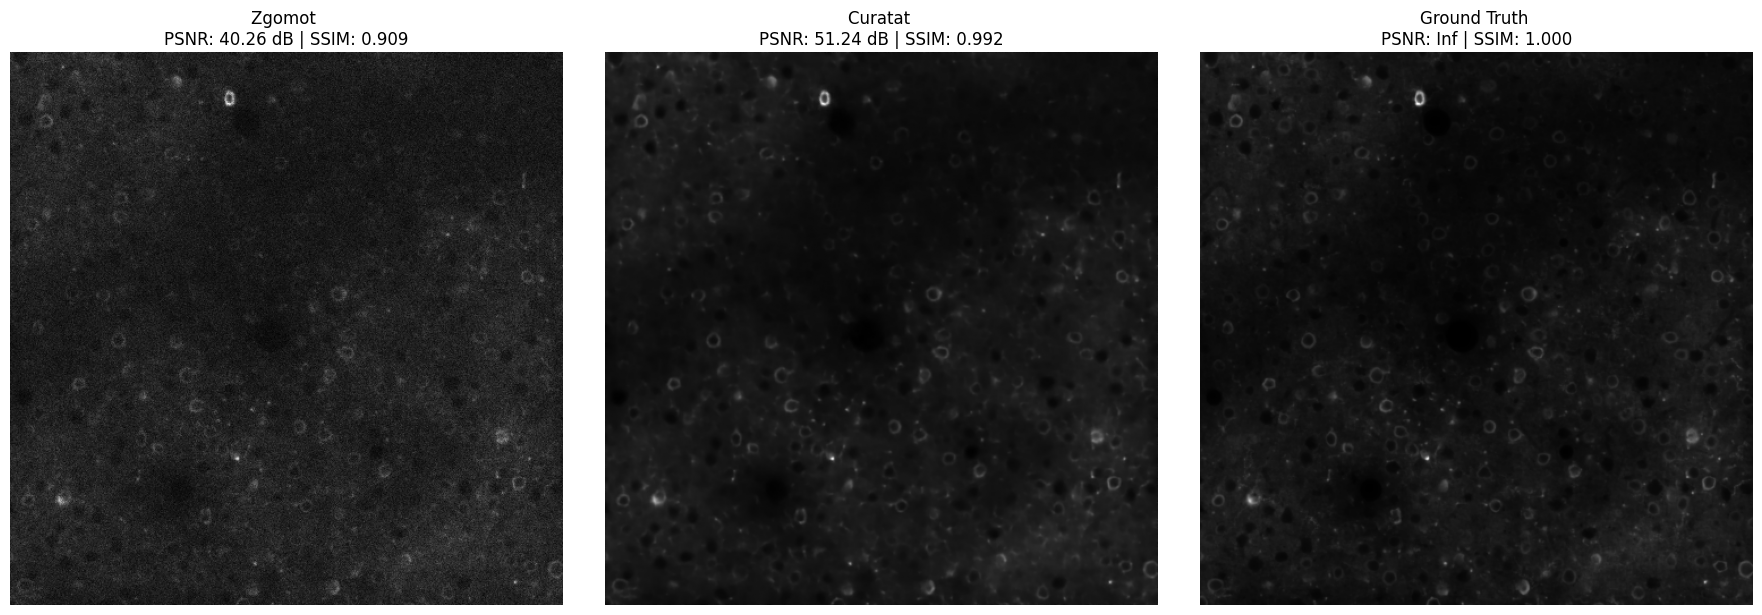

Modificare PSNR de la 40.26 dB la 51.24 dB
Modificare SSIM: de la 0.909 la 0.992


In [15]:
# Evaluarea si vizualizarea rezultatelor

# Se prelucreaza imaginile pe setul de test
predictii = model.predict(zgomot_test, batch_size=4)

#calculam valorile medii
lista_psnr_zgomot=[]
lista_psnr_pred=[]
lista_ssim_zgomot=[]
lista_ssim_pred=[]

for i in range (len(zgomot_test)):
  img_z=zgomot_test[i].squeeze()
  img_pred=predictii[i].squeeze()
  img_gt=gt_test[i].squeeze()
  lista_psnr_zgomot.append(peak_signal_noise_ratio(img_gt, img_z, data_range=1.0))
  lista_ssim_zgomot.append(structural_similarity(img_gt, img_z, data_range=1.0))
  lista_psnr_pred.append(peak_signal_noise_ratio(img_gt, img_pred, data_range=1.0))
  lista_ssim_pred.append(structural_similarity(img_gt, img_pred, data_range=1.0))

print(f"Rezultate medii pe tot setul de date: {len(zgomot_test)} cadre")
print(f"Medie PSNR zgomot: {np.mean(lista_psnr_zgomot):.2f}")
print(f"Medie PSNR pred: {np.mean(lista_psnr_pred):.2f}")
print(f"Medie SSIM zgomot: {np.mean(lista_ssim_zgomot):.3f}")
print(f"Medie SSIM pred: {np.mean(lista_ssim_pred):.3f}")

# Alegem un cadru aleatoriu din setul de testare
idx = np.random.randint(0, len(zgomot_test))
print(f"Cadrul ales pentru testare este {idx}")

# Elimina canalul de culoare pentru a putea executa testele
img_zgomot = zgomot_test[idx].squeeze()
img_curatat = predictii[idx].squeeze()
img_gt = gt_test[idx].squeeze()

# Calculam PSNR și SSIM
# PSNR -> verifica pixel cu pixel, cu cat are mai multi dB cu atat este mai buna
# SSIM -> verifica zonele, cu cat sunt mai asemanatoare cu atat e mai aproape de 1
# data_range=1.0 pentru ca am facut normalizarea intre [0,1]
psnr_zgomot = peak_signal_noise_ratio(img_gt, img_zgomot, data_range=1.0)
ssim_zgomot = structural_similarity(img_gt, img_zgomot, data_range=1.0)

psnr_pred = peak_signal_noise_ratio(img_gt, img_curatat, data_range=1.0)
ssim_pred = structural_similarity(img_gt, img_curatat, data_range=1.0)

# Afisarea rezultatelor
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(img_zgomot, cmap='gray')
plt.title(f"Zgomot \nPSNR: {psnr_zgomot:.2f} dB | SSIM: {ssim_zgomot:.3f}")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(img_curatat, cmap='gray')
plt.title(f"Curatat \nPSNR: {psnr_pred:.2f} dB | SSIM: {ssim_pred:.3f}")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_gt, cmap='gray')
plt.title("Ground Truth \nPSNR: Inf | SSIM: 1.000")
plt.axis('off')

plt.tight_layout()
plt.show()

print(f"Modificare PSNR de la {psnr_zgomot:.2f} dB la {psnr_pred:.2f} dB")
print(f"Modificare SSIM: de la {ssim_zgomot:.3f} la {ssim_pred:.3f}")